In [5]:
import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split


In [6]:
DATA_DIR = Path("../data/raw/IMDB Dataset.csv")

df = pd.read_csv(DATA_DIR)
print("dataset loaded successfully")

dataset loaded successfully


In [7]:
df.head(10)

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive
5,"Probably my all-time favorite movie, a story o...",positive
6,I sure would like to see a resurrection of a u...,positive
7,"This show was an amazing, fresh & innovative i...",negative
8,Encouraged by the positive comments about this...,negative
9,If you like original gut wrenching laughter yo...,positive


In [8]:
print("nb de ligne",df.shape[0])
print("nb de columns",df.shape[1])

nb de ligne 50000
nb de columns 2


In [9]:
df["sentiment"].value_counts()

sentiment
positive    25000
negative    25000
Name: count, dtype: int64

In [10]:
df["sentiment"].isnull().sum()

np.int64(0)

In [11]:
df["review"].isnull().sum()

np.int64(0)

In [12]:
df.duplicated().sum()

np.int64(418)

In [13]:
df.sentiment.unique()

<StringArray>
['positive', 'negative']
Length: 2, dtype: str

In [14]:
duplicated_rows = df[df.duplicated(keep=False)]
print("Duplicated rows:", len(duplicated_rows))
print(duplicated_rows.head(10))



Duplicated rows: 824
                                                review sentiment
42   Of all the films I have seen, this one, The Ra...  negative
84   We brought this film as a joke for a friend, a...  negative
140  Before I begin, let me get something off my ch...  negative
219  Ed Wood rides again. The fact that this movie ...  negative
245  I have seen this film at least 100 times and I...  positive
480  From director Barbet Schroder (Reversal of For...  negative
513  The story and the show were good, but it was r...  negative
636  I rented this thinking it would be pretty good...  negative
638  This movie has everything typical horror movie...  positive
701  I Enjoyed Watching This Well Acted Movie Very ...  positive


Suppression des valeurs dupliquées

In [15]:
# Store the initial dataset size
initial_size = len(df)

# Remove duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

# Calculate the number of removed rows
removed_rows = initial_size - len(df)

print(f"Initial number of reviews: {initial_size}")
print(f"Removed duplicate rows: {removed_rows}")
print(f"Final number of reviews: {len(df)}")

Initial number of reviews: 50000
Removed duplicate rows: 418
Final number of reviews: 49582


verification des doublons

In [16]:
df.duplicated().sum()

np.int64(0)

In [17]:
df.shape

(49582, 2)

In [18]:
df["sentiment"].value_counts()

sentiment
positive    24884
negative    24698
Name: count, dtype: int64

Le dataset reste equilibré

analyser la longueur des avis

In [19]:
# Calculate the number of words in each review
df["word_count"] = df["review"].apply(lambda x: len(str(x).split()))

# Display descriptive statistics
print(df["word_count"].describe())

count    49582.000000
mean       231.350167
std        171.542020
min          4.000000
25%        126.000000
50%        173.000000
75%        281.000000
max       2470.000000
Name: word_count, dtype: float64


Visualiser la distribution des longueurs

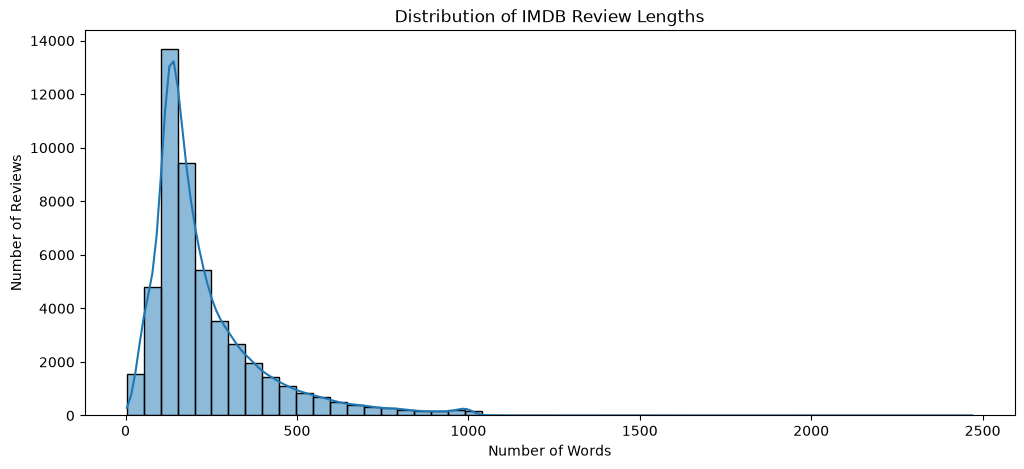

In [20]:
plt.figure(figsize=(12, 5))

sns.histplot(
    data=df,
    x="word_count",
    bins=50,
    kde=True
)

plt.title("Distribution of IMDB Review Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Number of Reviews")

plt.show()

La distribution est fortement asymétrique à droite (asymétrie positive).La grande majorité des avis se concentre entre 50 et 400 mots, avec un pic très net autour de 150 mots (où plus de 13 000 avis sont recensés).   On observe une longue queue vers la droite, ce qui indique qu'il existe quelques rares avis beaucoup plus longs (allant jusqu'à près de 2 500 mots), ainsi qu'une petite ondulation secondaire autour de 1 000 mots.   

In [21]:
# Compare review lengths by sentiment
print(
    df.groupby("sentiment")["word_count"]
      .describe()
)

             count        mean         std   min    25%    50%    75%     max
sentiment                                                                    
negative   24698.0  229.596607  165.103430   4.0  128.0  174.0  278.0  1522.0
positive   24884.0  233.090620  177.688169  10.0  125.0  172.0  284.0  2470.0


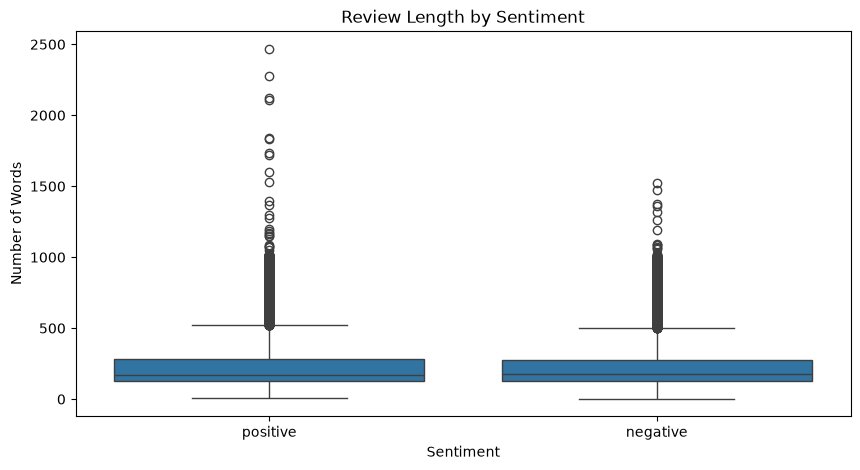

In [22]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="sentiment",
    y="word_count"
)

plt.title("Review Length by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Number of Words")

plt.show()

Les longueurs des avis positifs et négatifs sont globalement similaires.

Cela nous donne une information intéressante : la longueur d'un avis ne semble pas, à elle seule, être un indicateur évident de son sentiment.

Les avis positifs présentent quelques valeurs extrêmes plus élevées, mais cela ne signifie pas nécessairement qu'ils sont plus longs en moyenne.

Nous pouvons donc retenir :
- Pas de différence majeure de longueur entre les deux classes.
- Présence d'outliers dans les deux catégories.
- Conservation des avis longs pour ne pas perdre d'informations utiles.

In [23]:
# Create the processed data directory
processed_dir = Path("../data/processed")
processed_dir.mkdir(parents=True, exist_ok=True)

# Save the cleaned dataset
output_path = processed_dir / "imdb_cleaned.csv"

df.to_csv(output_path, index=False, encoding="utf-8")

print(f"Cleaned dataset saved to: {output_path}")
print(f"Final dataset shape: {df.shape}")

Cleaned dataset saved to: ..\data\processed\imdb_cleaned.csv
Final dataset shape: (49582, 3)


In [24]:
PATH = Path("../data/processed/imdb_cleaned.csv")
df = pd.read_csv(PATH)
print("Cleaned dataset loaded successfully")
print(f"Loaded dataset lenght: {len(df)}")

print(df.head(10))

Cleaned dataset loaded successfully
Loaded dataset lenght: 49582
                                              review sentiment  word_count
0  One of the other reviewers has mentioned that ...  positive         307
1  A wonderful little production. <br /><br />The...  positive         162
2  I thought this was a wonderful way to spend ti...  positive         166
3  Basically there's a family where a little boy ...  negative         138
4  Petter Mattei's "Love in the Time of Money" is...  positive         230
5  Probably my all-time favorite movie, a story o...  positive         119
6  I sure would like to see a resurrection of a u...  positive         150
7  This show was an amazing, fresh & innovative i...  negative         174
8  Encouraged by the positive comments about this...  negative         130
9  If you like original gut wrenching laughter yo...  positive          33


In [25]:
X=df['review']
Y=df['sentiment']

print("input values",X.head(10))
print("expected values",Y.head(10))

input values 0    One of the other reviewers has mentioned that ...
1    A wonderful little production. <br /><br />The...
2    I thought this was a wonderful way to spend ti...
3    Basically there's a family where a little boy ...
4    Petter Mattei's "Love in the Time of Money" is...
5    Probably my all-time favorite movie, a story o...
6    I sure would like to see a resurrection of a u...
7    This show was an amazing, fresh & innovative i...
8    Encouraged by the positive comments about this...
9    If you like original gut wrenching laughter yo...
Name: review, dtype: str
expected values 0    positive
1    positive
2    positive
3    negative
4    positive
5    positive
6    positive
7    negative
8    negative
9    positive
Name: sentiment, dtype: str


In [26]:
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=42,stratify=Y)

In [27]:
print("Training set size:", len(X_train))
print("Test set size:", len(X_test))

Training set size: 39665
Test set size: 9917


In [28]:
print("Training sentiment distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting sentiment distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training sentiment distribution:
sentiment
positive    50.187823
negative    49.812177
Name: proportion, dtype: float64

Testing sentiment distribution:
sentiment
positive    50.186548
negative    49.813452
Name: proportion, dtype: float64


In [29]:
df_train = pd.DataFrame({
    "review": X_train,
    "sentiment": y_train
}).reset_index(drop=True)

In [30]:
# Select 3 positive and 3 negative examples
few_shot_examples = (
    df_train.groupby("sentiment", group_keys=False)
    .head(3)
)

In [31]:
display(few_shot_examples)

,review,sentiment
0,I am one of Jehovah's Witnesses and I also wor...,positive
1,Amongst the standard one liner type action fil...,positive
2,Realty television crew are assigned to cover a...,negative
3,The funniest scene of this movie is probably w...,negative
4,There have been far too few mainstream films s...,positive
9,As someone has already mentioned on this board...,negative


In [32]:
print(few_shot_examples["sentiment"].value_counts())

sentiment
positive    3
negative    3
Name: count, dtype: int64


In [33]:
from prompt_engineering.llm_client import generate_response 
from prompt_engineering.prompts import zero_shot_prompt

test_review = """
This movie was absolutely fantastic.
The acting was excellent and the story was very engaging.
I really enjoyed watching it.
"""

prompt = zero_shot_prompt(test_review)

result = generate_response(prompt)

print("LLM response:")
print(result)

LLM response:
positive


In [45]:
import importlib
import prompt_engineering.llm_client as llm_client

importlib.reload(llm_client)

print(hasattr(llm_client, "normalize_sentiment"))

True


In [35]:
from prompt_engineering.llm_client import (
    generate_response,
    normalize_sentiment
)

raw_response = generate_response(
    zero_shot_prompt(test_review)
)

prediction = normalize_sentiment(raw_response)

print("Raw response:", raw_response)
print("Normalized prediction:", prediction)

Raw response: positive
Normalized prediction: positive


In [ ]:
from prompt_engineering.prompts import zero_shot_prompt
from prompt_engineering.llm_client import (
    generate_response,
    normalize_sentiment
)

# Selection d 100 reviews from the test set
X_test_sample = X_test.iloc[:100]
y_test_sample = y_test.iloc[:100]

predictions = []

for index, review in enumerate(X_test_sample):

    prompt = zero_shot_prompt(review)

    raw_response = generate_response(prompt)

    prediction = normalize_sentiment(raw_response)

    predictions.append(prediction)

    if (index + 1) % 10 == 0:
        print(f"Processed {index + 1}/100 reviews")

In [ ]:
from prompt_engineering.evaluation import evaluate_predictions

metrics_zero_shot = evaluate_predictions(
    y_test_sample,
    predictions
)

Evaluation Metrics
------------------
accuracy: 0.9000
precision: 1.0000
recall: 0.7619
f1_score: 0.8649

Classification Report:
              precision    recall  f1-score   support

    negative       0.85      1.00      0.92        58
    positive       1.00      0.76      0.86        42

    accuracy                           0.90       100
   macro avg       0.93      0.88      0.89       100
weighted avg       0.91      0.90      0.90       100



Conservation des metrics

In [ ]:
results = pd.DataFrame([{
    "technique": "Zero-Shot",
    "model": "llama3.2",
    "accuracy": metrics_zero_shot["accuracy"],
    "precision": metrics_zero_shot["precision"],
    "recall": metrics_zero_shot["recall"],
    "f1_score": metrics_zero_shot["f1_score"]
}])

results_path = Path("../results/metrics/prompting_metrics.csv")
results_path.parent.mkdir(parents=True, exist_ok=True)

results.to_csv(results_path, index=False)

print(results)

   technique     model  accuracy  precision    recall  f1_score
0  Zero-Shot  llama3.2       0.9        1.0  0.761905  0.864865


In [37]:
from prompt_engineering.prompts import few_shot_prompt
test_review = X_test_sample.iloc[3]

prompt = few_shot_prompt(
    test_review,
    few_shot_examples
)

raw_response = generate_response(prompt)

print("RAW RESPONSE:")
print(raw_response)

print("\nNORMALIZED:")
print(normalize_sentiment(raw_response))

RAW RESPONSE:
negative

NORMALIZED:
negative


In [38]:
predictions_few_shot = []

for index, review in enumerate(X_test_sample):

    prompt = few_shot_prompt(
        review,
        few_shot_examples
    )

    raw_response = generate_response(prompt)

    prediction = normalize_sentiment(raw_response)

    predictions_few_shot.append(prediction)

    if (index + 1) % 10 == 0:
        print(f"Processed {index + 1}/100 reviews")

Processed 10/100 reviews
Processed 20/100 reviews
Processed 30/100 reviews
Processed 40/100 reviews
Processed 50/100 reviews
Processed 60/100 reviews
Processed 70/100 reviews
Processed 80/100 reviews
Processed 90/100 reviews
Processed 100/100 reviews


In [39]:
from collections import Counter

print("Few-Shot prediction distribution:")
print(Counter(predictions_few_shot))

print("\nActual labels:")
print(Counter(y_test_sample))
print("Few-Shot prediction distribution:")
print(Counter(predictions_few_shot))

print("\nActual labels:")
print(Counter(y_test_sample))

Few-Shot prediction distribution:
Counter({'negative': 60, 'positive': 40})

Actual labels:
Counter({'negative': 58, 'positive': 42})
Few-Shot prediction distribution:
Counter({'negative': 60, 'positive': 40})

Actual labels:
Counter({'negative': 58, 'positive': 42})


In [40]:
from prompt_engineering.evaluation import evaluate_predictions

metrics_few_shot = evaluate_predictions(
    y_test_sample,
    predictions_few_shot
)

Evaluation Metrics
------------------
accuracy: 0.9600
precision: 0.9750
recall: 0.9286
f1_score: 0.9512

Classification Report:
              precision    recall  f1-score   support

    negative       0.95      0.98      0.97        58
    positive       0.97      0.93      0.95        42

    accuracy                           0.96       100
   macro avg       0.96      0.96      0.96       100
weighted avg       0.96      0.96      0.96       100



In [41]:
import pandas as pd
from pathlib import Path

metrics_path = Path("../results/metrics/prompting_metrics.csv")

few_shot_row = pd.DataFrame([{
    "technique": "Few-Shot",
    "model": "llama3.2",
    "accuracy": metrics_few_shot["accuracy"],
    "precision": metrics_few_shot["precision"],
    "recall": metrics_few_shot["recall"],
    "f1_score": metrics_few_shot["f1_score"]
}])

# Load previous results
existing_results = pd.read_csv(metrics_path)

# Avoid duplicate entries if the cell is executed again
existing_results = existing_results[
    existing_results["technique"] != "Few-Shot"
]

# Add Few-Shot results
all_results = pd.concat(
    [existing_results, few_shot_row],
    ignore_index=True
)

all_results.to_csv(metrics_path, index=False)

print(all_results)

   technique     model  accuracy  precision    recall  f1_score
0  Zero-Shot  llama3.2      0.90      1.000  0.761905  0.864865
1   Few-Shot  llama3.2      0.96      0.975  0.928571  0.951220


In [47]:
import importlib
import prompt_engineering.prompts as prompts

importlib.reload(prompts)

from prompt_engineering.prompts import role_based_prompt

In [48]:
test_review = X_test_sample.iloc[3]

prompt = role_based_prompt(test_review)

raw_response = generate_response(prompt)

print("RAW RESPONSE:")
print(raw_response)

print("\nNORMALIZED:")
print(normalize_sentiment(raw_response))

RAW RESPONSE:
negative

NORMALIZED:
negative


In [49]:
predictions_role_based = []

for index, review in enumerate(X_test_sample):

    prompt = role_based_prompt(review)

    raw_response = generate_response(prompt)

    prediction = normalize_sentiment(raw_response)

    predictions_role_based.append(prediction)

    if (index + 1) % 10 == 0:
        print(f"Processed {index + 1}/100 reviews")

Processed 10/100 reviews
Processed 20/100 reviews
Processed 30/100 reviews
Processed 40/100 reviews
Processed 50/100 reviews
Processed 60/100 reviews
Processed 70/100 reviews
Processed 80/100 reviews
Processed 90/100 reviews
Processed 100/100 reviews


In [50]:
print("Role-Based prediction distribution:")
print(Counter(predictions_role_based))

print("\nActual labels:")
print(Counter(y_test_sample))

Role-Based prediction distribution:
Counter({'negative': 72, 'positive': 28})

Actual labels:
Counter({'negative': 58, 'positive': 42})


In [51]:
metrics_role_based = evaluate_predictions(
    y_test_sample,
    predictions_role_based
)

Evaluation Metrics
------------------
accuracy: 0.8600
precision: 1.0000
recall: 0.6667
f1_score: 0.8000

Classification Report:
              precision    recall  f1-score   support

    negative       0.81      1.00      0.89        58
    positive       1.00      0.67      0.80        42

    accuracy                           0.86       100
   macro avg       0.90      0.83      0.85       100
weighted avg       0.89      0.86      0.85       100



In [52]:
metrics_path = Path("../results/metrics/prompting_metrics.csv")

role_based_row = pd.DataFrame([{
    "technique": "Role-Based",
    "model": "llama3.2",
    "accuracy": metrics_role_based["accuracy"],
    "precision": metrics_role_based["precision"],
    "recall": metrics_role_based["recall"],
    "f1_score": metrics_role_based["f1_score"]
}])

existing_results = pd.read_csv(metrics_path)

existing_results = existing_results[
    existing_results["technique"] != "Role-Based"
]

all_results = pd.concat(
    [existing_results, role_based_row],
    ignore_index=True
)

all_results.to_csv(metrics_path, index=False)

print(all_results)

    technique     model  accuracy  precision    recall  f1_score
0   Zero-Shot  llama3.2      0.90      1.000  0.761905  0.864865
1    Few-Shot  llama3.2      0.96      0.975  0.928571  0.951220
2  Role-Based  llama3.2      0.86      1.000  0.666667  0.800000


In [53]:
import prompt_engineering.prompts as prompts

importlib.reload(prompts)

from prompt_engineering.prompts import structured_prompt

test_review = X_test_sample.iloc[3]

prompt = structured_prompt(test_review)

raw_response = generate_response(prompt)

print("RAW RESPONSE:")
print(raw_response)

RAW RESPONSE:
{
    "sentiment": "negative"
}


In [58]:
import prompt_engineering.llm_client as llm_client

importlib.reload(llm_client)

from prompt_engineering.llm_client import normalize_json_sentiment

test_response = """
{
    "sentiment": "negative"
}
"""

print(normalize_json_sentiment(test_response))

negative


In [59]:
predictions_structured = []

for index, review in enumerate(X_test_sample):

    prompt = structured_prompt(review)

    raw_response = generate_response(prompt)

    prediction = normalize_json_sentiment(raw_response)

    predictions_structured.append(prediction)

    if (index + 1) % 10 == 0:
        print(f"Processed {index + 1}/100 reviews")

Processed 10/100 reviews
Processed 20/100 reviews
Processed 30/100 reviews
Processed 40/100 reviews
Processed 50/100 reviews
Processed 60/100 reviews
Processed 70/100 reviews
Processed 80/100 reviews
Processed 90/100 reviews
Processed 100/100 reviews


In [60]:
print("Structured prediction distribution:")
print(Counter(predictions_structured))

print("\nActual labels:")
print(Counter(y_test_sample))

Structured prediction distribution:
Counter({'negative': 60, 'positive': 39, 'unknown': 1})

Actual labels:
Counter({'negative': 58, 'positive': 42})
